# Gom cụm K-Means trên tập dữ liệu Wine

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [2]:
# Đọc dữ liệu từ file wine.data
columns = [
    'Class', 'Alcohol', 'Malic_acid', 'Ash', 'Alcalinity_of_ash',
    'Magnesium', 'Total_phenols', 'Flavanoids', 'Nonflavanoid_phenols',
    'Proanthocyanins', 'Color_intensity', 'Hue', 'OD280_OD315', 'Proline'
]

df = pd.read_csv('wine.data', header=None, names=columns)
df.head()

,Class,Alcohol,Malic_acid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,OD280_OD315,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [3]:
# Tách đặc trưng (bỏ cột Class) và chuẩn hóa dữ liệu
X = df.drop(columns=['Class'])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 1. Đánh giá số cụm K hợp lý (Elbow & Silhouette)

In [4]:
# Tính WCSS (Inertia) và Silhouette Score
inertia = []
sil_scores = []
k_range = range(2, 11)

for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    sil_scores.append(silhouette_score(X_scaled, labels))

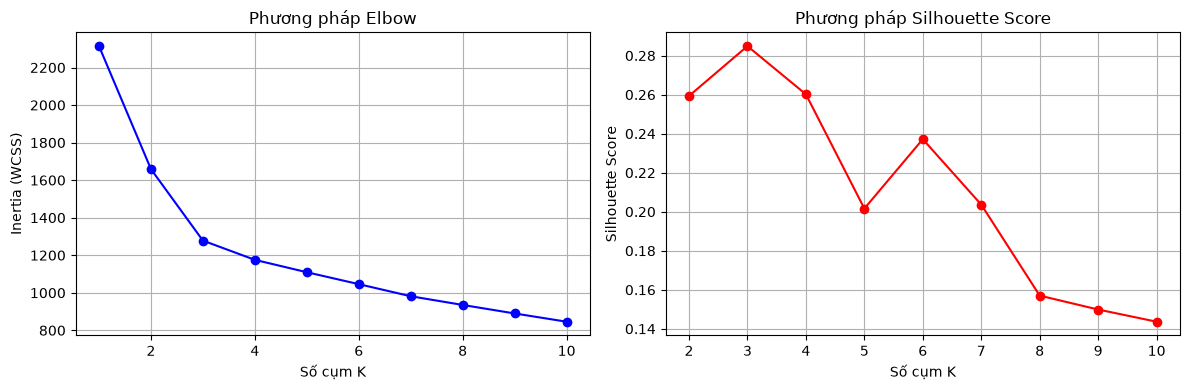

In [5]:
# Vẽ biểu đồ Elbow và Silhouette Score
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(range(1, 11), inertia, 'bo-')
ax[0].set_xlabel('Số cụm K')
ax[0].set_ylabel('Inertia (WCSS)')
ax[0].set_title('Phương pháp Elbow')
ax[0].grid(True)

ax[1].plot(k_range, sil_scores, 'ro-')
ax[1].set_xlabel('Số cụm K')
ax[1].set_ylabel('Silhouette Score')
ax[1].set_title('Phương pháp Silhouette Score')
ax[1].grid(True)

plt.tight_layout()
plt.show()

**Nhận xét chọn K:**
- Đường biểu diễn **Elbow** có điểm gập rõ rệt tại **K = 3** (sau K = 3, độ giảm quán tính chậm lại).
- Điểm **Silhouette Score** đạt giá trị cao nhất tại **K = 3** (~0.285).
=> Chọn **K = 3** là số cụm tối ưu và hợp lý nhất cho tập dữ liệu Wine.

## 2. Huấn luyện mô hình K-Means (K = 3)

In [6]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

df['Cluster'] = clusters
print('Số lượng mẫu ở mỗi cụm:')
print(df['Cluster'].value_counts())

Số lượng mẫu ở mỗi cụm:
Cluster
0    65
2    62
1    51
Name: count, dtype: int64


## 3. Trực quan hóa kết quả phân cụm

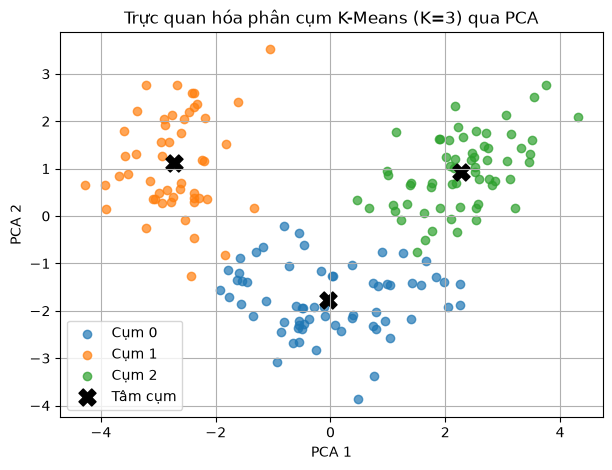

In [7]:
# Giảm 13 đặc trưng về 2 chiều bằng PCA để trực quan hóa
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
centers_pca = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(7, 5))
for c in range(3):
    plt.scatter(X_pca[clusters == c, 0], X_pca[clusters == c, 1], label=f'Cụm {c}', alpha=0.7)

# Vẽ tâm cụm (centroids)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c='black', s=150, marker='X', label='Tâm cụm')

plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('Trực quan hóa phân cụm K-Means (K=3) qua PCA')
plt.legend()
plt.grid(True)
plt.show()

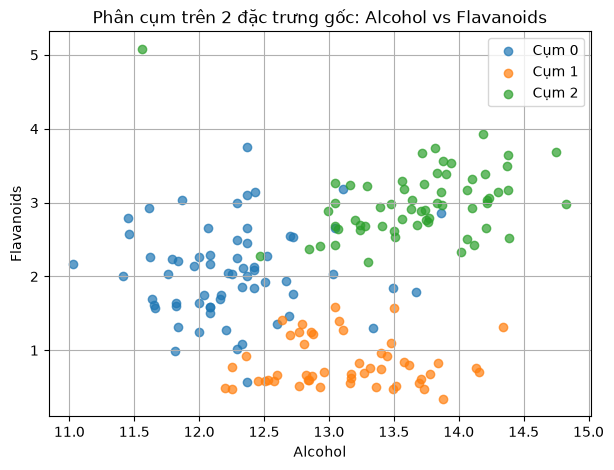

In [8]:
# Trực quan hóa thêm trên 2 đặc trưng gốc (Alcohol vs Flavanoids)
plt.figure(figsize=(7, 5))
for c in range(3):
    plt.scatter(df[df['Cluster'] == c]['Alcohol'], 
                df[df['Cluster'] == c]['Flavanoids'], 
                label=f'Cụm {c}', alpha=0.7)

plt.xlabel('Alcohol')
plt.ylabel('Flavanoids')
plt.title('Phân cụm trên 2 đặc trưng gốc: Alcohol vs Flavanoids')
plt.legend()
plt.grid(True)
plt.show()